# Lien entre le vent et les traumatismes

In [4]:
from fonctions_projet import*

## Récupération des données

### Données météo

## Récupération des données de vent depuis data.gouv.fr

Le code récupère automatiquement les données de vent de tous les départements :

1. **Liste des fichiers** : une requête à l'API de data.gouv.fr (`/api/1/datasets/...`) renvoie la fiche du jeu « Données climatologiques de base - quotidiennes ».
2. **Sélection des fichiers d'intérêt** : On ne garde que les fichiers départementaux couvrant la période 1950-2024 et contenant les variables de vent. On obtient une liste de dictionnaires, avec un fichier par département (DROM et COM inclus).
3. **Lecture de chaque fichier** : chaque fichier compressé (`csv.gz`) est lu directement depuis son lien, en ne gardant que quatre colonnes : `NUM_POSTE`, `AAAAMMJJ` (date), `FFM` (vent moyen) et `FXI3S` (rafale maximale).
4. **Filtre temporel** : seules les lignes à partir du 1er janvier 2016 sont conservées.
5. **Fusion** : les tableaux de tous les départements sont concaténés en un seul DataFrame, `meteoDF`.

**Temps d'exécution** : Les fichiers sont lus depuis le réseau à chaque exécution, ce qui est lent. (environ 5 minutes)

In [1]:
import requests
import pandas as pd
import re

"""
r = requests.get(
    "https://www.data.gouv.fr/api/1/datasets/donnees-climatologiques-de-base-quotidiennes/",
    headers={"X-Fields": "id,title,resources{title,format,type,latest}"},
    timeout=30,
)
"""
r = requests.get(
    "https://www.data.gouv.fr/api/1/datasets/donnees-climatologiques-de-base-quotidiennes/",
    headers={"X-Fields": "id,title,resources{title,format,type,latest}"},
)

fiche = r.json()

pattern = r'QUOT_departement_\d+_periode_1950-2024_RR-T-Vent'

fichiers_interet = [fiche['resources'][i] for i in range(len(fiche['resources'])) if re.fullmatch(pattern, fiche['resources'][i]['title']) ] ## On filtre sur les jeux de données qui nous intéressent

variables_vent_1 = ['NUM_POSTE', 'AAAAMMJJ', 'FFM', 'FXI3S'] ##, 'FF2M', 'FXY', 'DXY', 'FXI','DXI', 'FXI2', 'DXI2', 'FXI3S', 'DXI3S'
donnees_vent = []
nbre_departement = 0
for i in range(len(fichiers_interet)): ##len(fichiers_interet)
    print(f"nombre de départements importés : {nbre_departement}", end="\r")
    donnees_interet = pd.read_csv(fichiers_interet[i]['latest'],sep=';',dtype = {'NUM_POSTE' : str}, usecols = variables_vent_1, compression="gzip")  ##, parse_dates=["AAAAMMJJ"], date_format="%Y%m%d
    donnes_interet_filtre = donnees_interet[donnees_interet["AAAAMMJJ"] >= 20160101]
    donnees_vent.append(donnes_interet_filtre)
    nbre_departement += 1
print(f"nombre de départements importés : {len(fichiers_interet)}")

meteoDF = pd.concat(donnees_vent, ignore_index=True)

meteoDF.info()
display(meteoDF)

nombre de départements importés : 106
<class 'pandas.DataFrame'>
RangeIndex: 10273735 entries, 0 to 10273734
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   NUM_POSTE  str    
 1   AAAAMMJJ   int64  
 2   FFM        float64
 3   FXI3S      float64
dtypes: float64(2), int64(1), str(1)
memory usage: 393.1 MB


,NUM_POSTE,AAAAMMJJ,FFM,FXI3S
0,01014002,20160101,2.0,14.2
1,01014002,20160102,1.1,10.2
2,01014002,20160103,2.6,17.4
3,01014002,20160104,2.9,12.3
4,01014002,20160105,1.8,7.4
...,...,...,...,...
10273730,99138001,20170727,NaN,NaN
10273731,99138001,20170728,NaN,NaN
10273732,99138001,20170729,NaN,NaN
10273733,99138001,20170730,NaN,NaN


## Préparation du tableau de données

À partir du tableau d'origine (une ligne par station et par jour), on a effectué plusieurs transformations :

1. **Création de la variable `dep`** : elle est déduite des deux (ou trois) premiers chiffres du numéro de station (`NUM_POSTE`), qui correspondent au code du département.
2. **Agrégation par département** : pour chaque département (et chaque année), on a calculé la **moyenne** des valeurs de l'ensemble des stations du département, afin d'obtenir une seule mesure par département. Les valeurs manquantes (`NaN`) sont ignorées par le calcul de la moyenne, qui porte donc sur les valeurs disponibles. Cela évite de les traiter comme des zéros. Cependant une moyenne calculée sur peu de mesures est moins fiable.
3. **Renommage des variables** pour les rendre plus lisibles :
   - `FFM` devient `vent_moyen_ms` : moyenne quotidienne du vent moyenné sur 10 minutes, à 10 m (en m/s) ;
   - `FXI3S` devient `rafale_max_ms` : maximum quotidien du vent moyenné sur 3 secondes, à 10 m (en m/s).
4. **Création de variables temporelles** : extraction de la semaine ISO 8601 (`semaine_iso`) et de l'année ISO 8601 (`annee_iso`) à partir de la date.
5. **Création d'une clé de jointure** (`cle_semaine`) associant le département, la semaine ISO et l'année ISO.

In [2]:

meteoDF = meteoDF.rename(columns = {'AAAAMMJJ' : 'DATE'})
meteoDF['DATE'] = pd.to_datetime(meteoDF['DATE'], format = '%Y%m%d' )
meteoDF = meteoDF.rename(columns={"FFM": "vent_moyen_ms","FXI3S": "rafale_max_ms"})

meteoDF['dep'] = meteoDF['NUM_POSTE'].str[:2]
#meteoDF.loc[meteoDF['dep'].astype(int) > 95, "dep"] = meteoDF.loc[df_final1['dep'].astype(int) > 95, "NUM_POSTE"].str[:3]
meteoDF["semaine_iso"] = meteoDF["DATE"].dt.isocalendar().week
meteoDF["annee_iso"] = meteoDF["DATE"].dt.isocalendar().year
meteoDF["cle_semaine"] = list(zip(meteoDF["dep"], meteoDF["semaine_iso"], meteoDF["annee_iso"]))
meteoDF = meteoDF[["DATE", "annee_iso", "semaine_iso", "dep", "cle_semaine", "vent_moyen_ms", "rafale_max_ms"]]

meteo_jour = meteoDF.groupby(['DATE', 'dep'])[['vent_moyen_ms', 'rafale_max_ms']].mean().reset_index()
meteo_sem = meteoDF.groupby(['cle_semaine'])[['vent_moyen_ms', 'rafale_max_ms']].mean().reset_index()


/tmp/ipykernel_63306/627767387.py:2: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  meteoDF['DATE'] = pd.to_datetime(meteoDF['DATE'], format = '%Y%m%d' )


In [3]:
meteo_sem.head()

,cle_semaine,vent_moyen_ms,rafale_max_ms
0,"(01, 1, 2016)",1.919048,9.273810
1,"(01, 1, 2017)",1.843590,7.479487
2,"(01, 1, 2018)",2.392500,11.412500
3,"(01, 1, 2019)",2.421951,8.783333
4,"(01, 1, 2020)",1.230303,5.278571


In [4]:
meteo_jour.head()

,DATE,dep,vent_moyen_ms,rafale_max_ms
0,2016-01-01,01,1.633333,8.183333
1,2016-01-01,02,3.914286,11.042857
2,2016-01-01,03,2.460000,8.940000
3,2016-01-01,04,1.133333,5.925000
4,2016-01-01,05,1.482353,6.641667


### Cartographie de la vitesse moyenne du vent

Nous calculons la vitesse moyenne du vent par département, puis récupérons les contours géographiques français avec `Cartiflette`.

Les géométries des départements corses 2A et 2B sont fusionnées pour correspondre au code département 20 utilisé dans les données météorologiques.

Nous sélectionnons ensuite la France métropolitaine et fusionnons les données météorologiques avec les contours géographiques.

Enfin, nous projetons la carte en Lambert-93 (EPSG:2154) et représentons la vitesse moyenne du vent par département à l'aide d'une palette de couleurs. Les départements sans données apparaissent en gris.

Note: you may need to restart the kernel to use updated packages.


,geometry,INSEE_DEP,PAYS,LIBELLE_DEPARTEMENT,SOURCE
0,"MULTIPOLYGON (((9.24898 41.33694, 9.24861 41.3...",2B,France,Haute-Corse,IGN:EXPRESS-COG-CARTO-TERRITOIRE


,geometry,INSEE_DEP,PAYS,LIBELLE_DEPARTEMENT,SOURCE
0,"MULTIPOLYGON (((9.24898 41.33694, 9.24861 41.3...",20,France,Corse,IGN:EXPRESS-COG-CARTO-TERRITOIRE


,INSEE_DEP,PAYS,LIBELLE_DEPARTEMENT,SOURCE,geometry,dep,vent_moyen_ms
0,43,France,Haute-Loire,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"POLYGON ((770266.6 6473465.6, 770225.3 6473390...",43,3.221067
1,65,France,Hautes-Pyrénées,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"MULTIPOLYGON (((449840.3 6280811.2, 449889.1 6...",65,2.656058
2,29,France,Finistère,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"MULTIPOLYGON (((177277.8 6756845.8, 177208.5 6...",29,5.356026
3,22,France,Côtes-d'Armor,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"MULTIPOLYGON (((245382.2 6879188.9, 245375.4 6...",22,4.005757
4,38,France,Isère,IGN:EXPRESS-COG-CARTO-TERRITOIRE,"POLYGON ((863172.2 6525941.3, 862944.5 6525125...",38,2.078628


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 95 entries, 0 to 94
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   INSEE_DEP            95 non-null     str     
 1   PAYS                 95 non-null     str     
 2   LIBELLE_DEPARTEMENT  95 non-null     str     
 3   SOURCE               95 non-null     str     
 4   geometry             95 non-null     geometry
 5   dep                  95 non-null     str     
 6   vent_moyen_ms        93 non-null     float64 
dtypes: float64(1), geometry(1), str(5)
memory usage: 10.1 KB
None


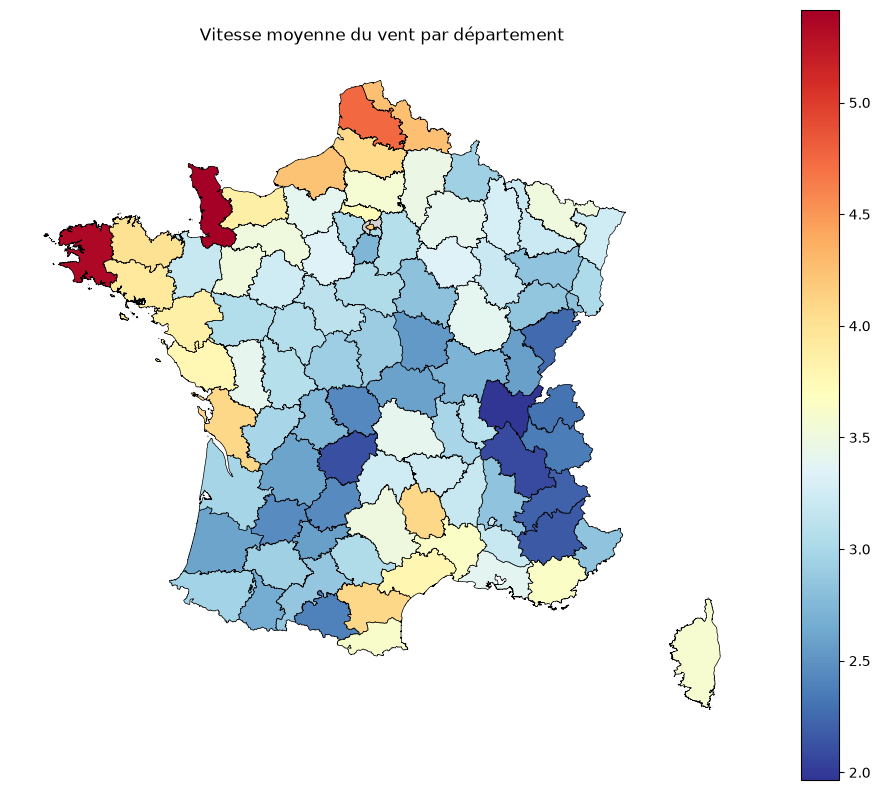

In [5]:
%pip install "duckdb<2" --quiet

# !pip install py7zr geopandas openpyxl tqdm s3fs ipywidgets --quiet
# !pip install PyYAML --quiet
# !pip install cartiflette --quiet


import geopandas as gpd
import matplotlib.pyplot as plt
from cartiflette import carti_download

donnee_vent_moyen_ms = meteoDF.groupby('dep')['vent_moyen_ms'].mean().reset_index()

departements = carti_download(
    values="France",
    crs=4326,
    borders="DEPARTEMENT",
    vectorfile_format="geojson",
    filter_by="FRANCE_ENTIERE",
    source="EXPRESS-COG-CARTO-TERRITOIRE",
    year=2022
)
departements = departements.drop(columns=["POPULATION"])

### On fusionne les géométries des départments Corse
corse = departements[departements["INSEE_DEP"].isin(["2A", "2B"])].dissolve()

display(corse)

### On corrige les données de corse
 
corse["INSEE_DEP"] = "20"
corse["LIBELLE_DEPARTEMENT"] = "Corse"

display(corse)

### On retire les deux anciennes lignes
departements = departements[~departements["INSEE_DEP"].isin(["2A", "2B"])]


### On intègre la Corse sous le code département 20
departements = pd.concat(
    [departements, corse],
    ignore_index=True
)


departements_metropole = departements[departements["INSEE_DEP"].astype(int) <= 95]


carte = departements_metropole.merge(
    donnee_vent_moyen_ms,
    left_on="INSEE_DEP",
    right_on="dep",
    how="left"

)
### On change le système de coordonnées en système Lambert-93

carte = carte.to_crs(2154)
display(carte.head())
print(carte.info())


carte.plot(
    column="vent_moyen_ms",
    cmap="RdYlBu_r",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
    figsize=(12, 10),
    missing_kwds={"color": "lightgrey"}
)

plt.title("Vitesse moyenne du vent par département")
plt.axis("off")
plt.show()

### Description de la carte : vitesse moyenne du vent par département

La carte représente, pour chaque département de France métropolitaine, la vitesse moyenne du vent (en m/s) sur l'ensemble de la période étudiée. Les valeurs vont d'environ 2,3 m/s (bleu foncé) à plus de 5,3 m/s (rouge foncé).

**Départements où le vent moyen est le plus élevé**
- Le **Finistère (29)** et la **Manche (50)** sont les deux départements les plus ventés, avec des moyennes supérieures à 5 m/s.
- Le **Pas-de-Calais (62)** et le **Nord (59)** ressortent aussi, avec des valeurs comprises entre 4,5 et 5 m/s environ.
- Plusieurs départements de l'ouest affichent des valeurs élevées, autour de 3,5 à 4 m/s : les **Côtes-d'Armor (22)**, le **Morbihan (56)**, la **Loire-Atlantique (44)**, la **Vendée (85)** et la **Charente-Maritime (17)**.
- Dans le sud, l'**Aude (11)** et la **Lozère (48)** se détachent également, avec des valeurs proches de 4 m/s.

**Départements où le vent moyen est le plus faible**
- Les valeurs les plus basses (entre 2,3 et 2,6 m/s environ) se concentrent dans le sud-est : l'**Isère (38)**, la **Drôme (26)**, les **Hautes-Alpes (05)** et les **Alpes-de-Haute-Provence (04)**.
- Quelques départements du centre-sud (comme la **Corrèze (19)**) et du sud-ouest (comme les **Hautes-Pyrénées (65)**) présentent aussi des valeurs faibles.

**Départements aux valeurs intermédiaires**
- La grande majorité des départements du centre et de l'est de la France se situent entre 2,8 et 3,5 m/s.
- La **Corse (20)** se situe autour de 3,5 m/s.

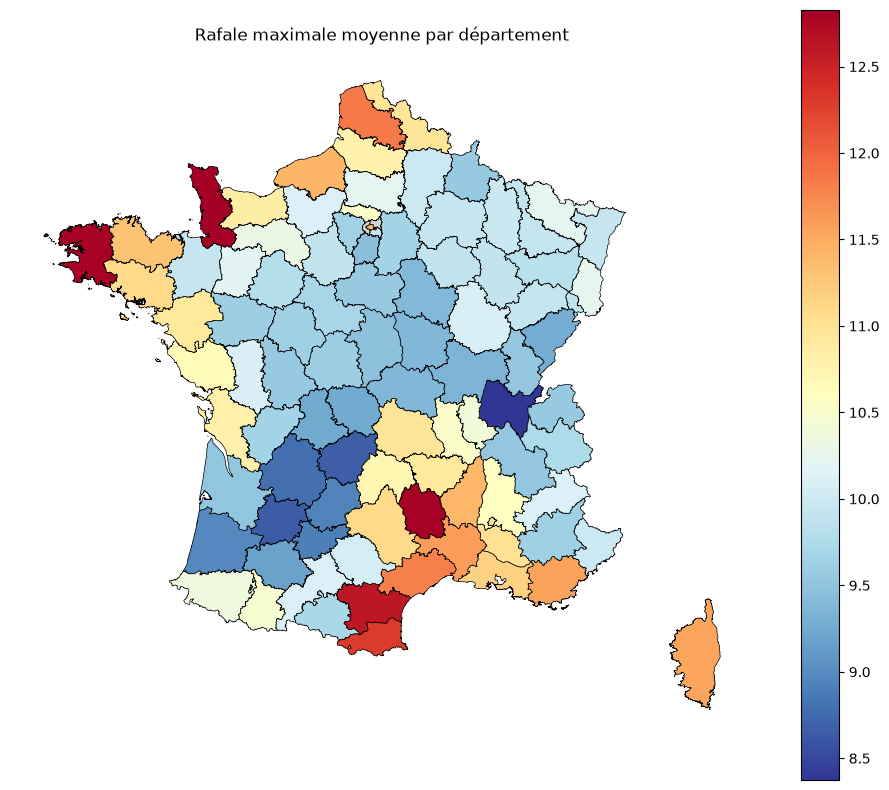

In [6]:
donnee_rafale_max_ms = meteoDF.groupby('dep')['rafale_max_ms'].mean().reset_index()

carte = departements_metropole.merge(
    donnee_rafale_max_ms,
    left_on="INSEE_DEP",
    right_on="dep",
    how="left"

)

### On change le système de coordonnées en système Lambert-93
carte = carte.to_crs(2154)

carte.plot(
    column="rafale_max_ms",
    cmap="RdYlBu_r",
    legend=True,
    edgecolor="black",
    linewidth=0.5,
    figsize=(12, 10),
    missing_kwds={"color": "lightgrey"}
)

plt.title("Rafale maximale moyenne par département")
plt.axis("off")
plt.show()

### Description de la carte : rafale maximale moyenne par département

La carte représente, pour chaque département de France métropolitaine, la rafale maximale moyenne (en m/s) sur l'ensemble de la période étudiée. Les valeurs vont d'environ 8,8 m/s (bleu foncé) à plus de 12,8 m/s (rouge foncé). L'écart entre départements est donc plus resserré que pour le vent moyen : il faut garder en tête que l'échelle de couleurs ne démarre pas à zéro, ce qui accentue visuellement les différences.

**Départements où les rafales sont les plus fortes**
- Le **Finistère (29)** et la **Manche (50)** présentent les rafales les plus élevées, au-dessus de 12,5 m/s, comme pour le vent moyen.
- La **Lozère (48)** ressort également en rouge foncé.
- L'**Aude (11)** et l'**Hérault (34)** affichent aussi des valeurs très élevées (autour de 12,3 à 12,5 m/s), suivis du **Pas-de-Calais (62)** (environ 12 m/s).
- Les départements du pourtour méditerranéen comme le **Gard (30)**, le **Var (83)** et la **Corse (20)** se situent entre 11,5 et 12 m/s.
- Plusieurs départements de l'ouest sont dans une tranche intermédiaire haute (11 à 11,7 m/s) : les **Côtes-d'Armor (22)**, le **Morbihan (56)**, l'**Ile-et-Vilaine (35)**, la **Loire-Atlantique (44)** et la **Vendée (85)**.

**Départements où les rafales sont les plus faibles**
- Le minimum (environ 8,8 m/s) se situe dans un département de l'est de la région Rhône-Alpes (probablement l'**Isère (38)**), qui apparaît isolé en bleu foncé.
- Un ensemble de départements du centre-sud-ouest affiche des valeurs basses (9 à 9,3 m/s) : la **Dordogne (24)**, le **Lot (46)**, la **Corrèze (19)** et le **Lot-et-Garonne (47)** notamment.

**Départements aux valeurs intermédiaires**
- La majorité des départements du centre, du nord-est et de l'est se situent entre 9,5 et 10,3 m/s.

**Comparaison avec la carte du vent moyen**
- Les deux cartes se ressemblent : le **Finistère** et la **Manche** sont en tête dans les deux cas, et le centre de la France reste plutôt calme.
- Quelques différences : la **Lozère**, l'**Aude** et l'**Hérault** ressortent bien plus nettement pour les rafales que pour le vent moyen, et la **Corse** passe d'une valeur intermédiaire à une valeur élevée.
- Inversement, le **Nord (59)** ressort moins pour les rafales que pour le vent moyen.

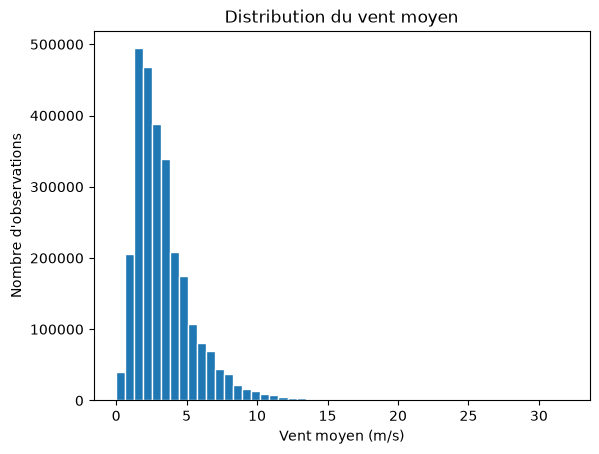

In [7]:
import matplotlib.pyplot as plt

def histogramme(x, titre, xlabel, bins=30):
    plt.hist(x, bins=bins, edgecolor="white")
    plt.title(titre)
    plt.xlabel(xlabel)
    plt.ylabel("Nombre d'observations")
    plt.show()

histogramme(meteoDF["vent_moyen_ms"], "Distribution du vent moyen", "Vent moyen (m/s)", 50)

### Distribution du vent moyen

Le pic se situe entre 1,5 et 2 m/s (environ 490 000 observations), et la grande majorité des valeurs sont comprises entre 1 et 5 m/s. Les effectifs décroissent ensuite rapidement : au-delà de 10 m/s, les barres sont à peine visibles.

L'axe s'étend jusqu'à environ 30 m/s, car quelques observations isolées atteignent ces valeurs, mais elles sont trop peu nombreuses pour apparaître sur le graphique.

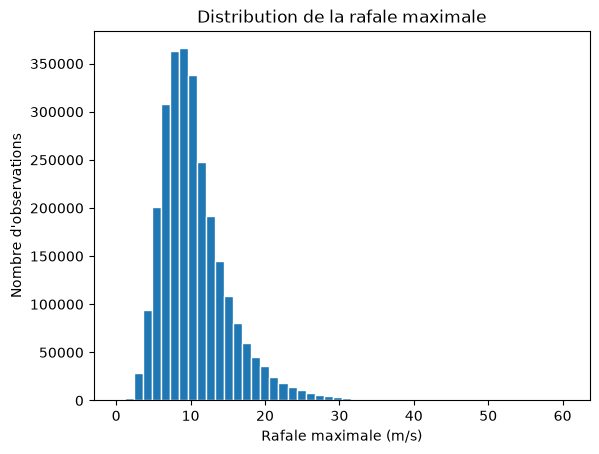

In [8]:
histogramme(meteoDF["rafale_max_ms"], "Distribution de la rafale maximale", "Rafale maximale (m/s)", 50)

### Distribution de la rafale maximale

Le pic se situe entre 8 et 10 m/s (environ 365 000 observations), et la grande majorité des valeurs sont comprises entre 5 et 15 m/s. Les effectifs diminuent ensuite progressivement : les barres deviennent très faibles au-delà de 25 m/s et disparaissent visuellement vers 30 m/s.

### Données traumatismes

In [9]:
import pandas as pd

bobos = pd.read_parquet("https://minio.lab.sspcloud.fr/jvalade/projet_2A_S1/traumatisme-passages-aux-urgences-et-actes-sos-medecins-departement.parquet")
nb_hospi = pd.read_parquet("https://minio.lab.sspcloud.fr/jvalade/projet_2A_S1/series_longues_passages_urgences_2017_2023.parquet")

nb_hospi["date"] = pd.to_datetime(nb_hospi["date"])
nb_hospi["semaine"] = nb_hospi["date"].dt.isocalendar().week

bobos["date_complet"] = pd.to_datetime(bobos["date_complet"])
bobos["semaine"] = bobos["date_complet"].dt.isocalendar().week

nb_hospi["cle_semaine"] = list(zip(nb_hospi["dep"], nb_hospi["semaine"], nb_hospi["date"].dt.isocalendar().year)) #on utilise zip pour concaténer les colonnes selon l'axis 1
bobos["cle_semaine"] = list(zip(bobos["dep"], bobos["semaine"], bobos["date_complet"].dt.isocalendar().year))

nb_hospi_semaine = nb_hospi.groupby("cle_semaine")[["nb_passages"]].sum()

nb_bobos = bobos.merge(nb_hospi_semaine, on="cle_semaine", how= 'inner')

nb_bobos = nb_bobos[nb_bobos["sursaud_cl_age_gene"] == "Tous âges"]

nb_bobos["nb_traumas"] = nb_bobos["taux_passages_trauma_sau"] * nb_bobos["nb_passages"] / 100_000 #le taux de passage correspond au nombre pour 100 000 passages
nb_bobos = nb_bobos[["cle_semaine", "date_complet", "dep", "nb_traumas"]] #on ne garde que les variables d'intérêt

nb_bobos.head()
display(nb_bobos.info())


<class 'pandas.DataFrame'>
Index: 15288 entries, 1 to 61151
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype        
---  ------        --------------  -----        
 0   cle_semaine   15288 non-null  object       
 1   date_complet  15288 non-null  datetime64[s]
 2   dep           15288 non-null  str          
 3   nb_traumas    15288 non-null  float64      
dtypes: datetime64[s](1), float64(1), object(1), str(1)
memory usage: 629.4+ KB


None

### Données crime

In [10]:
DEPARTMENTS = {
    '01': 'Ain', '02': 'Aisne', '03': 'Allier', '04': 'Alpes-de-Haute-Provence', '05': 'Hautes-Alpes','06': 'Alpes-Maritimes', '07': 'Ardèche', '08': 'Ardennes', '09': 'Ariège', '10': 'Aube', '11': 'Aude','12': 'Aveyron', '13': 'Bouches-du-Rhône','14': 'Calvados', '15': 'Cantal', '16': 'Charente','17': 'Charente-Maritime', '18': 'Cher', '19': 'Corrèze', '2A': 'Corse-du-Sud', '2B': 'Haute-Corse','21': 'Côte-d\'Or', '22': 'Côtes-d\'Armor', '23': 'Creuse', '24': 'Dordogne', '25': 'Doubs', '26': 'Drôme','27': 'Eure', '28': 'Eure-et-Loir', '29': 'Finistère', '30': 'Gard', '31': 'Haute-Garonne', '32': 'Gers','33': 'Gironde', '34': 'Hérault', '35': 'Ille-et-Vilaine', '36': 'Indre', '37': 'Indre-et-Loire','38': 'Isère', '39': 'Jura', '40': 'Landes', '41': 'Loir-et-Cher', '42': 'Loire', '43': 'Haute-Loire','44': 'Loire-Atlantique', '45': 'Loiret', '46': 'Lot', '47': 'Lot-et-Garonne', '48': 'Lozère','49': 'Maine-et-Loire', '50': 'Manche', '51': 'Marne', '52': 'Haute-Marne', '53': 'Mayenne','54': 'Meurthe-et-Moselle', '55': 'Meuse', '56': 'Morbihan', '57': 'Moselle', '58': 'Nièvre', '59': 'Nord','60': 'Oise', '61': 'Orne', '62': 'Pas-de-Calais', '63': 'Puy-de-Dôme', '64': 'Pyrénées-Atlantiques','65': 'Hautes-Pyrénées', '66': 'Pyrénées-Orientales', '67': 'Bas-Rhin', '68': 'Haut-Rhin', '69': 'Rhône','70': 'Haute-Saône', '71': 'Saône-et-Loire', '72': 'Sarthe', '73': 'Savoie', '74': 'Haute-Savoie','75': 'Paris', '76': 'Seine-Maritime', '77': 'Seine-et-Marne', '78': 'Yvelines', '79': 'Deux-Sèvres','80': 'Somme', '81': 'Tarn', '82': 'Tarn-et-Garonne', '83': 'Var', '84': 'Vaucluse', '85': 'Vendée','86': 'Vienne', '87': 'Haute-Vienne', '88': 'Vosges', '89': 'Yonne', '90': 'Territoire de Belfort','91': 'Essonne', '92': 'Hauts-de-Seine', '93': 'Seine-Saint-Denis', '94': 'Val-de-Marne', '95': 'Val-d\'Oise','971': 'Guadeloupe', '972': 'Martinique', '973': 'Guyane', '974': 'La Réunion', '976': 'Mayotte',
}


In [11]:
import requests
import bs4
import pandas as pd

!pip install lxml --quiet

url = "https://fr.wikipedia.org/wiki/Liste_d'affaires_criminelles_fran%C3%A7aises_depuis_1900"

req = requests.get(url, headers={"User-Agent":"School Data Science Project"})

request_text = req.content
page = bs4.BeautifulSoup(request_text, "lxml")

tableaux = page.find_all('table', {'class':'wikitable sortable'})

faitsDiv = list()
for tableau in tableaux :
    table_body = tableau.find('tbody')
    rows = table_body.find_all('tr')
    liste = list()
    for row in rows:
        cols = row.find_all('td')
        cols = [ele.text.strip() for ele in cols]
        if len(cols) > 0 : 
            liste.append(cols)
    faitsDiv.append(liste)

liste_dataf = list()
for tableau in faitsDiv :
    liste_dataf.append(pd.DataFrame(tableau))

liste_colonnes = list()

for tableau in tableaux :
    table_body = tableau.find('tbody')
    rows = table_body.find_all('tr')
    for row in rows:
        cols = row.find_all('th')
        if len(cols) > 0 : 
            cols = [ele.get_text(separator=' ').strip().title() for ele in cols]
            liste_colonnes.append(cols)

for i in range(len(liste_dataf)):
    liste_dataf[i].columns = liste_colonnes[i]

faitsDivDF = pd.concat(liste_dataf)
faitsDivDF = faitsDivDF.reset_index(drop=True)

faitsDivDF = faitsDivDF[["Département(S) [ Note 2 ]", "Résumé"]]

import re

import pandas as pd

MOIS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet",
        "août", "septembre", "octobre", "novembre", "décembre"]
MOTIF = re.compile(r"(\d{1,2})(?:er)? (" + "|".join(MOIS) + r") (\d{4})")


def extraire_date(texte):
    """
    Renvoie la première date rencontrée au format JJ-MM-AAAA, Nan si pas de date dans le texte
    """
    m = MOTIF.search(str(texte))
    if not m:
        return None
    jour, mois, annee = m.groups()
    return f"{int(jour):02d}-{MOIS.index(mois) + 1:02d}-{annee}"

faitsDivDF = faitsDivDF[["Département(S) [ Note 2 ]", "Résumé"]]
faitsDivDF.columns = ["Département" , "Résumé"]

for i in range(len(faitsDivDF)) : 
    faitsDivDF.loc[i, "date"] = extraire_date(faitsDivDF.loc[i, "Résumé"])

departement_df = pd.DataFrame.from_dict(DEPARTMENTS, orient = 'index', columns=["Département"])
departement_df = departement_df.reset_index()
departement_df.columns = ["Numéro", "Département"]

faitsDivDF = faitsDivDF.merge(departement_df, on="Département", how = "inner")

faitsDivDF = faitsDivDF.dropna()
faitsDivDF["date"] = pd.to_datetime(faitsDivDF["date"], format= f'%d-%m-%Y')
faitsDivDF.columns = ["Département", "Résumé", "DATE", "dep"]
faitsDivDF.head()
display(faitsDivDF.info())

<class 'pandas.DataFrame'>
Index: 310 entries, 1 to 380
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Département  310 non-null    str           
 1   Résumé       310 non-null    str           
 2   DATE         310 non-null    datetime64[us]
 3   dep          310 non-null    str           
dtypes: datetime64[us](1), str(3)
memory usage: 60.8 KB


/tmp/ipykernel_63306/3635876817.py:30: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  liste_dataf.append(pd.DataFrame(tableau))


None

### Jointure des données

In [12]:
ventBobos = meteo_sem.merge(nb_bobos, on = "cle_semaine", how = "inner")

ventBobos.head()
display(ventBobos.info())

<class 'pandas.DataFrame'>
RangeIndex: 14508 entries, 0 to 14507
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype        
---  ------         --------------  -----        
 0   cle_semaine    14508 non-null  object       
 1   vent_moyen_ms  14040 non-null  float64      
 2   rafale_max_ms  14040 non-null  float64      
 3   date_complet   14508 non-null  datetime64[s]
 4   dep            14508 non-null  str          
 5   nb_traumas     14508 non-null  float64      
dtypes: datetime64[s](1), float64(3), object(1), str(1)
memory usage: 710.3+ KB


None

In [13]:
ventCrime = meteo_jour.merge(faitsDivDF, on = ["DATE", "dep"], how = "inner")

ventCrime.head()

,DATE,dep,vent_moyen_ms,rafale_max_ms,Département,Résumé
0,2016-01-05,01,2.200000,8.883333,Ain,"Le 5 janvier 2016 à Ambérieu-en-Bugey, Anne-Ch..."
1,2016-03-13,71,4.057143,12.757143,Saône-et-Loire,"Le 13 mars 2016 à la Clayette, Valérie Bacot, ..."
2,2016-06-13,78,3.116667,8.250000,Yvelines,"Le 13 juin 2016 à Magnanville, assassinat d'un..."
3,2016-07-14,06,3.815000,18.342105,Alpes-Maritimes,"Le 14 juillet 2016 à Nice, Mohamed Lahouaiej-B..."
4,2016-07-26,76,2.585714,7.971429,Seine-Maritime,"Le 26 juillet 2016 à Saint-Étienne-du-Rouvray,..."


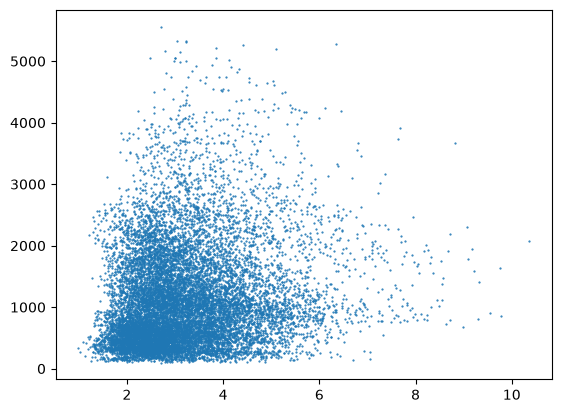

In [14]:
from matplotlib import pyplot as plt

x = ventBobos["vent_moyen_ms"]
y = ventBobos["nb_traumas"]

plt.scatter(x,y, s=0.3)
plt.show()


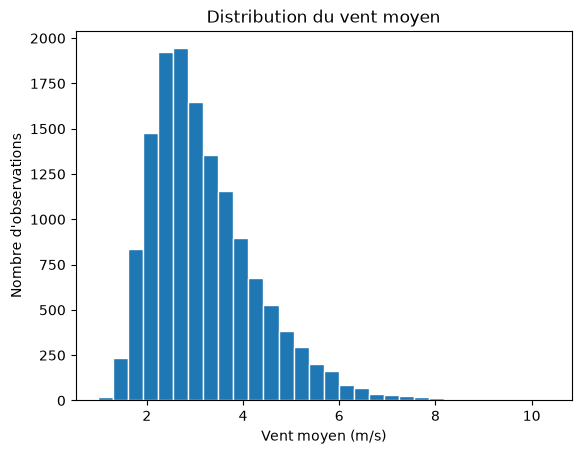

In [15]:

### Note : graphique à comparer avec les moyennes de vent, sinon inutile


from matplotlib import pyplot as plt

x = ventBobos["vent_moyen_ms"]
plt.hist(x, bins=30, edgecolor="white")
plt.title("Distribution du vent moyen")
plt.xlabel("Vent moyen (m/s)")
plt.ylabel("Nombre d'observations")
plt.show()


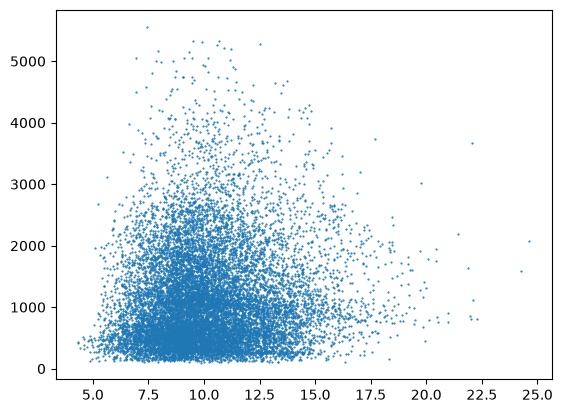

In [16]:
x = ventBobos["rafale_max_ms"]
y = ventBobos["nb_traumas"]

plt.scatter(x,y, s=0.3)
plt.show()

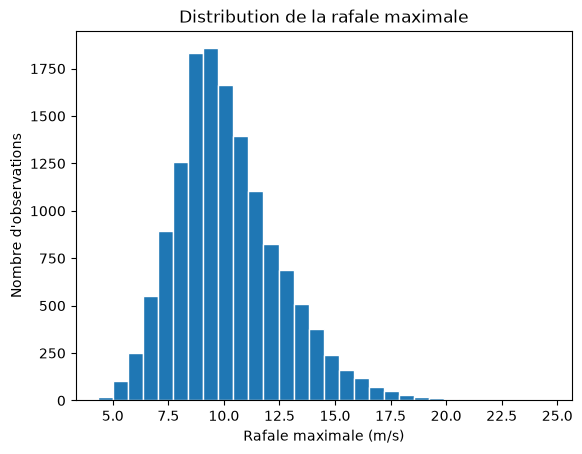

In [17]:
### Note : graphique à comparer avec les moyennes de vent

x = ventBobos["rafale_max_ms"]

plt.hist(x, bins=30, edgecolor="white")
plt.title("Distribution de la rafale maximale")
plt.xlabel("Rafale maximale (m/s)")
plt.ylabel("Nombre d'observations")
plt.show()

Il y a beaucoup d'observations les semaines de faible vent ainsi que d'observations dans la moyenne.\
On normalise ???

In [ ]:
reg = regression_lineaire(ventBobos ,"vent_moyen_ms", "nb_traumas")

In [ ]:
reg = regression_lineaire(ventBobos, "rafale_max_ms", "nb_traumas")